In [49]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

### Generate and Prepare Data

In [ ]:
#from aif360.datasets import BinaryLabelDataset
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import numpy as np
from sklearn.compose import make_column_transformer, make_column_selector
from sklearn.compose import ColumnTransformer
from sklearn.compose import make_column_selector as selector
import random
import pandas as pd
import copy

# https://inria.github.io/scikit-learn-mooc/python_scripts/03_categorical_pipeline_column_transformer.html
def preprocessDataset(train_path='/media/data_dump/Mohit/facct23_samplebias_data/adult/raw/original_train.csv', test_path='/media/data_dump/Mohit/facct23_samplebias_data/adult/raw/original_test.csv'):
    dataset_train = pd.read_csv(train_path)
    dataset_test = pd.read_csv(test_path)

    sensitive = 'race'
    label = 'category'
    dropAttrs = ['race', 'category', 'sex']
    labelReplacementDict = {'Survived':1, 'Recidivated':0}
    sensitiveReplacementDict = {'African-American':0, 'Caucasian':1}
    privileged_groups = [{'race':0}]
    unprivileged_groups = [{'race': 1}]
    favorable_label = 1
    unfavorable_label = 0

    # Separate out labels and sensitive Attributes
    y_train = dataset_train[label]
    z_train = dataset_train[sensitive]
    x_train = dataset_train.drop(columns=dropAttrs)
    y_test = dataset_test[label]
    z_test = dataset_test[sensitive]
    x_test = dataset_test.drop(columns=dropAttrs)
    # Binarize label and sensitive attribute
    y_train.replace(labelReplacementDict, inplace=True)
    y_test.replace(labelReplacementDict, inplace=True)

    z_train.replace(sensitiveReplacementDict, inplace=True)
    z_test.replace(sensitiveReplacementDict, inplace=True)

    # Preprocess Data
    numerical_columns_selector = selector(dtype_exclude=object)
    categorical_columns_selector = selector(dtype_include=object)
    numerical_columns = numerical_columns_selector(x_train)
    categorical_columns = categorical_columns_selector(x_train)
    categorical_preprocessor = OneHotEncoder(handle_unknown="ignore")
    numerical_preprocessor = StandardScaler()

    preprocessor = ColumnTransformer([
        ('one-hot-encoder', categorical_preprocessor, categorical_columns),
        ('standard_scaler', numerical_preprocessor, numerical_columns)]).fit(x_train)

    tempTrain = preprocessor.transform(x_train)
    tempTest = preprocessor.transform(x_test)
    """ct = make_column_transformer(
       (StandardScaler(),
        make_column_selector(dtype_include=np.number)),
       (OneHotEncoder(),
        make_column_selector(dtype_include=object)))
    ct.fit(x_train)
    print(ct)
    tempTrain = ct.transform(x_train)
    tempTest = ct.transform(x_test)"""
    # Sometimes we get a sparse CSR matrix, sometimes we get a ndarray
    if isinstance(tempTrain, np.ndarray):
        preprocessed_x_train = pd.DataFrame(tempTrain.tolist(), columns=[f'feature_{i}' for i in range(tempTrain.shape[1])])
        preprocessed_x_test = pd.DataFrame(tempTest.tolist(), columns=[f'feature_{i}' for i in range(tempTest.shape[1])])
    else:
        preprocessed_x_train = pd.DataFrame(tempTrain.toarray(), columns=[f'feature_{i}' for i in range(tempTrain.shape[1])])
        preprocessed_x_test = pd.DataFrame(tempTest.toarray(), columns=[f'feature_{i}' for i in range(tempTest.shape[1])])
    preprocessed_x_train[label] = y_train
    preprocessed_x_test[label] = y_test
    preprocessed_x_train[sensitive] = z_train
    preprocessed_x_test[sensitive] = z_test

    return preprocessed_x_train, preprocessed_x_test

In [71]:
train_data, test_data = preprocessDataset(train_path='compas_splits/train_split_1', test_path='compas_splits/test_split_1', dataset='compas')

/tmp/ipykernel_21587/3456558854.py:34: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y_train.replace(labelReplacementDict, inplace=True)
/tmp/ipykernel_21587/3456558854.py:35: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y_test.replace(labelReplacementDict, inplace=True)
/tmp/ipykernel_21587/3456558854.py:37: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `p

In [72]:
train_data

,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,...,feature_335,feature_336,feature_337,feature_338,feature_339,feature_340,feature_341,feature_342,category,race
0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,-0.720482,-0.14625,-0.19186,-0.244159,-0.712066,1,0
1,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,-1.146674,-0.14625,-0.19186,-0.244159,-0.504036,1,0
2,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.046663,-0.14625,-0.19186,-0.244159,0.744138,1,0
3,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,-0.976197,-0.14625,-0.19186,-0.244159,-0.712066,1,0
4,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,-1.146674,-0.14625,-0.19186,-0.244159,-0.296007,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4211,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,-0.890959,-0.14625,-0.19186,-0.244159,-0.296007,0,1
4212,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.984285,-0.14625,-0.19186,-0.244159,0.328080,0,1
4213,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,-0.038576,-0.14625,-0.19186,-0.244159,0.328080,0,1
4214,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,-0.464767,-0.14625,-0.19186,-0.244159,-0.504036,0,1


In [73]:
# df = pd.read_csv("compas-scores-two-years.csv")

# # all_data = fetch_adult()
# # X = all_data['data']
# # Y = all_data['target']
# # cols = all_data['feature_names']
# # X = X.drop(columns=['fnlwgt', 'education-num', 'race']) # Dropping the other sensitive attributes
# # A = X.pop('sex')

# # # Replace Y with 0/1 and A with 0/1
# # Y = (Y == '>50K').astype(int)
# # A = (A == 'Male').astype(int)

# # df = df[(df["days_b_screening_arrest"] <= 30)
# #         & (df["days_b_screening_arrest"] >= -30)
# #         & (df["is_recid"] != -1)
# #         & (df["c_charge_degree"] != 'O')
# #         & (df["score_text"] != 'N/A')
# #         & (df['race'].isin(['African-American', 'Caucasian']))].reset_index(drop=True)
# df = df[(df['race'].isin(['African-American', 'Caucasian']))].reset_index(drop=True)

# print(df.columns)

# columns = ["id", "age", "age_cat", "sex", "race",  #demographics
#            "juv_fel_count", "juv_misd_count", "juv_other_count", "priors_count", #criminal history
#            "c_charge_degree", "c_charge_desc", #current charges
#            "score_text", "decile_score", #compas results for current charges -> target for regression (COMPAS scores for general recidivism)
#            "r_charge_degree", "r_charge_desc", #commited crimes (general) within 2 years after COMPAS scoring (no feature for final model, but relevant for feature engineering)
#            "two_year_recid"] #target for classification
# df = df[columns]


# #target_attribute = "decile_score"
# target_attribute = 'two_year_recid'
# sensitive_attributes = ["sex", "race"]#, "age", "dob", "age_cat"]
# choice_attribute = "race"
# # Drop all other sensitive attributes
# df = df.drop(columns=[attr for attr in sensitive_attributes if attr != choice_attribute])

# # Binarize label and sensitive attribute
# #df[target_attribute] = (df[target_attribute] >= 5).astype(int)
# #df[choice_attribute] = (df[choice_attribute] == 'Male').astype(int)
# df[choice_attribute] = (df[choice_attribute] == 'Caucasian').astype(int)

# # Relabel target to Y and sensitive to A within df
# df = df.rename(columns={target_attribute: "Y", choice_attribute: "A"})

# #df.drop(columns=["id"], inplace=True)  # drop id column
# # Possible correlation with target
# #df.drop(columns=["is_violent_recid", "decile_score", "score_text"], inplace=True)
# #df.drop(columns=['screening_date', 'v_screening_date', 'decile_score.1', 'priors_count.1'], inplace=True)

# Y = df.pop("Y")
# A = df.pop("A")
# X = df

In [74]:
# subgroups = {
#     '00': [],
#     '01': [],
#     '10': [],
#     '11': []
# }

# # Check Y and A and add indices to subgroups
# for i in range(len(Y)):
#     y_val = int(Y.iloc[i])
#     a_val = int(A.iloc[i])
#     key = f"{y_val}{a_val}"
#     subgroups[key].append(i)

# for i in subgroups:
#     print(i, len(subgroups[i]))

# # Calculate positive rate difference
# print(len(subgroups['11'])/(len(subgroups['11']) + len(subgroups['01'])) - len(subgroups['10'])/(len(subgroups['10']) + len(subgroups['00'])))

In [87]:
# import pandas as pd

# train_indices = []
# test_indices = []
# for key, indices in subgroups.items():
#     np.random.shuffle(indices)
#     split_point = int(0.7 * len(indices))
#     train_indices.extend(indices[:split_point])
#     test_indices.extend(indices[split_point:])

# train_X = X.iloc[train_indices]
# train_Y = Y.iloc[train_indices]
# train_A = A.iloc[train_indices]

# test_X = X.iloc[test_indices]
# test_Y = Y.iloc[test_indices]
# test_A = A.iloc[test_indices]

train_X = train_data.drop(columns=['category', 'race'])
train_Y = train_data['category']
train_A = train_data['race']

test_X = test_data.drop(columns=['category', 'race'])
test_Y = test_data['category']
test_A = test_data['race']

# Add A back to features
train_X['A'] = train_A
test_X['A'] = test_A

# # Process Categorical Columns and Numerical columns
# # categorical_cols = ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'native-country', 'A']
# # numerical_cols = ['age', 'hours-per-week', 'capital-gain', 'capital-loss']

# categorical_cols = train_X.select_dtypes(include=['object', 'category']).columns.tolist()
# numerical_cols = train_X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# from sklearn.preprocessing import OneHotEncoder, StandardScaler
# from sklearn.compose import ColumnTransformer
# from sklearn.pipeline import Pipeline
# # Preprocessing for numerical and categorical data, handle NaNs
# preprocessor = ColumnTransformer(
#     transformers=[
#         ('num', StandardScaler(), numerical_cols),
#         ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
#     ])
# preprocessor.fit(train_X)
# train_X = preprocessor.transform(train_X).toarray()
# test_X = preprocessor.transform(test_X).toarray()

In [88]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
# Train a logistic regression model on the embeddings
clf = LogisticRegression()
#clf = RandomForestClassifier(n_estimators=100)
clf.fit(train_X, train_Y)
print("Logistic Regression training accuracy: ", clf.score(train_X, train_Y))
test_preds = clf.predict(test_X)
print("Logistic Regression test accuracy: ", accuracy_score(test_Y, test_preds))
print(classification_report(test_Y, test_preds))

from fairlearn.metrics import true_positive_rate_difference, demographic_parity_difference

print('TPR Diff: ', true_positive_rate_difference(test_Y, test_preds, sensitive_features=test_A))
print('DP Diff: ', demographic_parity_difference(test_Y, test_preds, sensitive_features=test_A))

train_soft = clf.predict_proba(train_X)[:, 1]
test_soft = clf.predict_proba(test_X)[:, 1]

Logistic Regression training accuracy:  0.7125237191650854
Logistic Regression test accuracy:  0.6650898770104068
              precision    recall  f1-score   support

           0       0.66      0.60      0.63       498
           1       0.67      0.72      0.69       559

    accuracy                           0.67      1057
   macro avg       0.66      0.66      0.66      1057
weighted avg       0.66      0.67      0.66      1057

TPR Diff:  0.2049685437293729
DP Diff:  0.26300437711946695


In [89]:
# Plot soft labels as a histogram
# Plot color coded histogram (group 0: red, group 1: blue)
# plt.figure(figsize=(10, 5))
# #plt.hist(train_soft[np.where((train_Y == 0) & (train_A == 0))], bins=50, alpha=0.5, color='red', label='Group 0, Label 0')
# #plt.hist(train_soft[np.where((train_Y == 1) & (train_A == 0))], bins=50, alpha=0.5, color='orange', label='Group 0, Label 1')
# #plt.hist(train_soft[np.where((train_Y == 0) & (train_A == 1))], bins=50, alpha=0.5, color='blue', label='Group 1, Label 0')
# #plt.hist(train_soft[np.where((train_Y == 1) & (train_A == 1))], bins=50, alpha=0.5, color='cyan', label='Group 1, Label 1')
# plt.legend()
# plt.title('Histogram of Soft Labels by Group and True Label')
# plt.xlabel('Predicted Probability of Positive Class')
# plt.ylabel('Frequency')
# plt.show()

#plt.figure(figsize=(10, 5))
#plt.hist(train_c[np.where((train_y == 0) & (train_a == 0))[0]], bins=50, alpha=0.5, color='red', label='Group 0, Label 0', density=True)
#plt.hist(train_c[np.where((train_y == 1) & (train_a == 0))[0]], bins=50, alpha=0.5, color='orange', label='Group 0, Label 1', density=True)
#plt.hist(train_c[np.where((train_y == 0) & (train_a == 1))[0]], bins=50, alpha=0.5, color='blue', label='Group 1, Label 0', density=True)
#plt.hist(train_c[np.where((train_y == 1) & (train_a == 1))[0]], bins=50, alpha=0.5, color='cyan', label='Group 1, Label 1', density=True)

In [90]:
# # plot the distribution
# def plot_distribution(samples, sensitive, labels, means, covars):
#     plt.figure(figsize=(10, 6))
#     color_00 = 'blue'
#     color_01 = 'orange'
#     color_10 = 'green'
#     color_11 = 'red'

#     indices_00 = np.where((labels == 0) & (sensitive == 0))[0]
#     indices_01 = np.where((labels == 0) & (sensitive == 1))[0]
#     indices_10 = np.where((labels == 1) & (sensitive == 0))[0]
#     indices_11 = np.where((labels == 1) & (sensitive == 1))[0]

#     plt.scatter(samples[indices_00, 0], samples[indices_00, 1], color=color_00, alpha=0.5, label='Label=0, Sensitive=0')
#     plt.scatter(samples[indices_01, 0], samples[indices_01, 1], color=color_01, alpha=0.5, label='Label=0, Sensitive=1')
#     plt.scatter(samples[indices_10, 0], samples[indices_10, 1], color=color_10, alpha=0.5, label='Label=1, Sensitive=0')
#     plt.scatter(samples[indices_11, 0], samples[indices_11, 1], color=color_11, alpha=0.5, label='Label=1, Sensitive=1')
#     plt.scatter(means['00'][0], means['00'][1], color=color_00, marker='x', s=100, label='Mean 00')
#     plt.scatter(means['01'][0], means['01'][1], color=color_01, marker='x', s=100, label='Mean 01')
#     plt.scatter(means['10'][0], means['10'][1], color=color_10, marker='x', s=100, label='Mean 10')
#     plt.scatter(means['11'][0], means['11'][1], color=color_11, marker='x', s=100, label='Mean 11')
#     plt.title('Distribution of Samples with Sensitive Attributes and Labels')
#     plt.xlabel('Feature 1')
#     plt.ylabel('Feature 2')
#     plt.legend()
#     plt.grid()
#     plt.show()
# plot_distribution(samples, sensitive, labels, means, covars)

### Baselines

In [94]:
from oxonfair import FairPredictor
from sklearn.linear_model import LogisticRegression
from oxonfair import group_metrics as gm

def train_oxon(train_x, train_y, train_a, test_x, test_y, test_a, metric='dp', classifier='lr', tolerance=0.0001):
    # https://arxiv.org/pdf/2407.13710
    # https://github.com/oxfordinternetinstitute/oxonfair/blob/master/examples/fairret.ipynb
    # Split train into a val set (30%)
    subgroups = {
        '00': [],
        '01': [],
        '10': [],
        '11': []
    }
    for i in range(len(train_y)):
        y_val = int(train_y.iloc[i])
        a_val = int(train_a.iloc[i])
        key = f"{y_val}{a_val}"
        subgroups[key].append(i)
    train_indices = []
    val_indices = []
    for key, indices in subgroups.items():
        np.random.shuffle(indices)
        split_point = int(0.7 * len(indices))
        train_indices.extend(indices[:split_point])
        val_indices.extend(indices[split_point:])
    # x is a numpy array, y and a are pandas series

    val_x = train_x[val_indices]
    val_y = train_y.iloc[val_indices]
    val_a = train_a.iloc[val_indices]
    train_x = train_x[train_indices]
    train_y = train_y.iloc[train_indices]
    train_a = train_a.iloc[train_indices]
    # Data is a numpy array, convert to pandas dataframe
    x_train_df = pd.DataFrame(train_x, columns=[f'feature_{i}' for i in range(train_x.shape[1])])
    x_train_df['A'] = train_a.values
    # convert target to array
    y_train = train_y.values
    x_val_df = pd.DataFrame(val_x, columns=[f'feature_{i}' for i in range(val_x.shape[1])])
    x_val_df['A'] = val_a.values
    y_val = val_y.values
    x_test_df = pd.DataFrame(test_x, columns=[f'feature_{i}' for i in range(test_x.shape[1])])
    x_test_df['A'] = test_a.values
    y_test = test_y.values

    if classifier == 'lr':
        predictor = LogisticRegression()
        predictor.fit(x_train_df, y_train)
    else:
        assert False, "Only logistic regression is supported currently"
    
    fair_predictor = FairPredictor(
        predictor=predictor,
        validation_data={
            'data': x_val_df,
            'target': y_val,
            'groups': 'A'
        },
        groups='A',

    )

    if metric == 'dp':
        fair_metric = gm.demographic_parity
    elif metric == 'eop':
        fair_metric = gm.equal_opportunity
    fair_predictor.fit(
        objective=gm.accuracy,
        constraint=fair_metric,
        value=tolerance
    )
    tradeoff = fair_predictor.evaluate(
        data={
            'data': x_test_df,
            'target': y_test,
            'groups': 'A'
        }
    )
    tradeoff = fair_predictor.frontier_scores()
    return tradeoff

train_X = train_X.values
test_X = test_X.values

oxon_vals =  train_oxon(train_X, train_Y, train_A, test_X, test_Y, test_A, metric='dp', classifier='lr')
oxon_errs = 1 - oxon_vals[0]
oxon_unfs = oxon_vals[1]

Groups passed twice to fairpredictor both as part of the dataset and as an argument. The argument will be used.


In [95]:
import sys
import os
import pandas as pd
sys.path.append(os.path.join(os.getcwd(), 'FairPareto'))

from FairPareto.fairpareto.core import FairParetoClassifier

# Load your data (X should include the sensitive attribute column)
# Modified the class to work with custom soft labels
#feature_group = np.column_stack((samples, sensitive))
data_df = pd.DataFrame(train_X)
data_df['sensitive'] = train_A
from sklearn.ensemble import RandomForestClassifier

clf = FairParetoClassifier(soft=[
    train_soft[np.where(train_A == 0)[0]],
    train_soft[np.where(train_A == 1)[0]]
], sensitive_column='sensitive', gamma_values= list(np.linspace(0, 0.5, 31)), verbose=True)
clf.fit(data_df, train_Y)

pareto_front = clf.get_pareto_front()
print(pareto_front)

/home/mohit/.conda/envs/llms/lib/python3.11/site-packages/xgboost/core.py:390: FutureWarning: Your system has an old version of glibc (< 2.28). We will stop supporting Linux distros with glibc older than 2.28 after **May 31, 2025**. Please upgrade to a recent Linux distro (with glibc >= 2.28) to use future versions of XGBoost.
Note: You have installed the 'manylinux2014' variant of XGBoost. Certain features such as GPU algorithms or federated learning are not available. To use these features, please upgrade to a recent Linux distro with glibc 2.28+, and install the 'manylinux_2_28' variant.
  warnings.warn(


FairPareto: Starting fit process...
  - Data shape: (4216, 345)
  - Strategy: histogram, n_bins: 10, k: 2
  - Preparing dataset...
  - Group 0 size: 2537, Group 1 size: 1679
  - Using provided calibrated classifier...
  - Computing Pareto front...
    - Applying histogram binning...
    - Optimization parameters: n=10, m=10, alpha=0.398
    - Running optimization for 31 gamma values...


/home/mohit/.conda/envs/llms/lib/python3.11/site-packages/cvxpy/atoms/affine/vec.py:40: FutureWarning: 
    You didn't specify the order of the vec expression. The default order
    used in CVXPY is Fortran ('F') order. This default will change to match NumPy's
    default order ('C') in a future version of CVXPY.
    To suppress this warning, please specify the order explicitly.
    
  warnings.warn(vec_order_warning, FutureWarning)
/home/mohit/.conda/envs/llms/lib/python3.11/site-packages/cvxpy/atoms/affine/reshape.py:68: FutureWarning: 
    You didn't specify the order of the reshape expression. The default order
    used in CVXPY is Fortran ('F') order. This default will change to match NumPy's
    default order ('C') in a future version of CVXPY.
    To suppress this warning, please specify the order explicitly.
    
  warnings.warn(reshape_order_warning, FutureWarning)


  - Pareto front computed with 31 points
FairPareto: Fit complete!
{np.float64(0.0): np.float64(0.3282204634844388), np.float64(0.016666666666666666): np.float64(0.3270976250102188), np.float64(0.03333333333333333): np.float64(0.3259747865931807), np.float64(0.05): np.float64(0.3248519481919184), np.float64(0.06666666666666667): np.float64(0.3237291093655381), np.float64(0.08333333333333333): np.float64(0.3226062713468882), np.float64(0.1): np.float64(0.3220043432673688), np.float64(0.11666666666666667): np.float64(0.3214639860648179), np.float64(0.13333333333333333): np.float64(0.3209236295410305), np.float64(0.15): np.float64(0.32038327230072), np.float64(0.16666666666666666): np.float64(0.31984291551551103), np.float64(0.18333333333333332): np.float64(0.3193025587434948), np.float64(0.2): np.float64(0.31876220224569285), np.float64(0.21666666666666667): np.float64(0.31822184550851296), np.float64(0.23333333333333334): np.float64(0.3176814884332539), np.float64(0.25): np.float64(0.31

In [96]:
# # Imports
# import numpy as np
# import torch
# import torch.nn as nn


# class FERMI(torch.nn.Module):

#     def __init__(self, X_train, X_test, Y_train, Y_test, S_train, S_test, batch_size=64, epochs=2000, lam=10):

#         super(FERMI, self).__init__()

#         self.X_train = X_train
#         self.Y_train = Y_train
#         self.X_test = X_test
#         self.Y_test = Y_test
#         self.S_train = S_train
#         self.S_test = S_test

#         self.batch_size = batch_size
#         self.epochs = epochs

#         self.n = X_train.shape[0]
#         self.d = X_train.shape[1]
#         self.m = Y_train.shape[1]
#         if self.m == 1:
#             self.m = 2

#         self.k = S_train.shape[1]

#         self.W = nn.Parameter(torch.zeros(self.k, self.m))  # k: Support of sensitive attributes, m: number of labels
#         self.theta = nn.Parameter(torch.zeros(self.d, 1))

#         sums = self.S_train.sum(axis=0) / self.n
#         print(sums)

#         print(sums.shape)

#         final_entries = []
#         for item in sums:
#             final_entries.append(1.0 / np.sqrt(item))

#         self.P_s = np.diag(sums)

#         self.P_s_sqrt_inv = torch.from_numpy(np.diag(final_entries)).double()
#         print(self.P_s_sqrt_inv)
#         self.lam = lam

#     def forward(self, X):
#         outputs = torch.mm(X.double(), self.theta.double())
#         logits = torch.sigmoid(outputs)
#         return logits

#     def fairness_regularizer(self, X, S):

#         current_batch_size = X.shape[0]
#         summation = 0

#         Y_hat = torch.sigmoid(torch.matmul(X, self.theta.double()))

#         for i in range(current_batch_size):
#             Y_hat_i = torch.zeros(self.m, self.m).double()
#             Y_hat_i[0][0] = 1.0 - Y_hat[i]
#             Y_hat_i[1][1] = Y_hat[i]

#             W_gram = torch.matmul(torch.t(self.W.double()), self.W.double())  # W^T W
#             summation -= torch.trace(torch.matmul(Y_hat_i, W_gram))

#             P_ys = torch.zeros(self.m, self.k).double()
#             P_ys[0][0] = S[i][0] * (1.0 - Y_hat[i])
#             P_ys[0][1] = S[i][1] * (1.0 - Y_hat[i])
#             P_ys[1][0] = S[i][0] * (Y_hat[i])
#             P_ys[1][1] = S[i][1] * (Y_hat[i])
#             prob_matrix_mul = torch.matmul(P_ys, self.P_s_sqrt_inv)
#             summation += 2 * torch.trace(torch.matmul(prob_matrix_mul, self.W.double())) - 1
#             #summation += 2 * torch.trace(torch.matmul(prob_matrix_mul, torch.t(self.W.double())))

#         return self.lam * summation


# ###
# def FERMI_Logistic_Regression(fermi, batch_size=64, epochs=1000, initial_epochs=300,
#                               initial_learning_rate=1, learning_rate_min=0.01, learning_rate_max=0.01, test_mode='on', test_report_at_every_x_epoch=10):

#     X = fermi.X_train
#     S_Matrix = fermi.S_train
#     Y = fermi.Y_train
#     XTest = fermi.X_test
#     STest = fermi.S_test
#     YTest = fermi.Y_test

#     criterion = torch.nn.BCELoss()
#     minimizer = torch.optim.SGD([fermi.theta, fermi.W], lr=initial_learning_rate)

#     for ep in range(epochs + initial_epochs):
#         if test_mode == 'on' and ep % test_report_at_every_x_epoch == test_report_at_every_x_epoch - 1:
#             print("Epoch Number: ", ep + 1)
#             # Test:
#             pre_logits = np.dot(XTest, fermi.theta.detach().numpy())
#             output_logits = 1 / (1 + np.exp(-pre_logits))
#             final_preds = output_logits > 0.5
#             test = YTest == 1
#             acc = final_preds == test
#             true_preds = acc.sum(axis=0)
#             print("Accuracy: ", true_preds[0] / output_logits.shape[0] * 100, "%")

#             final_preds = np.array(final_preds)
#             intersections = np.dot(final_preds.T, STest)
#             numbers = STest.sum(axis=0)

#             group1 = intersections[0][0] / numbers[0]
#             group2 = intersections[0][1] / numbers[1]
#             print("DP Violation: ", np.abs(group1 - group2))

#         number_of_iterations = X.shape[0] // batch_size
#         for i in range(number_of_iterations):

#             start = i * batch_size
#             end = (i + 1) * batch_size

#             current_batch_X = X[start:end]
#             current_batch_Y = Y[start:end]
#             current_batch_S = S_Matrix[start:end]

#             XTorch = torch.from_numpy(current_batch_X).double()
#             logits = fermi(XTorch)
#             YTorch = torch.from_numpy(current_batch_Y).double()
#             STorch = torch.from_numpy(current_batch_S).double()

#             # # Ensure Y is between 0 and 1 (convert if necessary)
#             # if YTorch.max() > 1.0 or YTorch.min() < 0.0:
#             #     YTorch = (YTorch - YTorch.min()) / (YTorch.max() - YTorch.min())
            
#             # logits = fermi.forward(XTorch)
            
#             # # Clamp logits to ensure they're in valid range
#             # logits = torch.clamp(logits, min=1e-7, max=1-1e-7)

#             if ep < initial_epochs:
#                 loss_min = criterion(logits, YTorch)
#             else:
#                 loss_min = criterion(logits, YTorch) + fermi.fairness_regularizer(XTorch, STorch)
#             # loss_min = criterion(logits, YTorch)

#             minimizer.zero_grad()
#             loss_min.backward()

#             if ep >= initial_epochs:
#                 fermi.theta.grad.data.mul_(learning_rate_min / initial_learning_rate)
#                 fermi.W.grad.data.mul_(-learning_rate_max / initial_learning_rate)

#             minimizer.step()
#     return fermi.theta, fermi.W

# from tqdm import tqdm

# all_weights = {}

# for lam in np.arange(10, 1000, 10):
#     fermi_instance = FERMI(train_embeddings, test_embeddings, train_soft.reshape(-1, 1), test_soft.reshape(-1, 1),
#                         S_train=np.eye(2)[train_attrs], S_test=np.eye(2)[test_attrs], batch_size=64, epochs=2000, lam=lam)
#     all_weights[lam] = FERMI_Logistic_Regression(fermi_instance)

In [97]:
from fairlearn.reductions import ExponentiatedGradient, DemographicParity, TruePositiveRateParity
from sklearn.linear_model import LogisticRegression
from tqdm import tqdm
# Train Exp-grad
# Repeat for DP
eps_cls = {}
# for eps in tqdm([0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1]):
#     #constraint = DemographicParity()
#     constraint = TruePositiveRateParity()
#     mitigator = ExponentiatedGradient(LogisticRegression(), constraint, eps=eps)
#     mitigator.fit(samples, labels, sensitive_features=sensitive)
#     eps_cls[eps] = mitigator
#for eps in tqdm([0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3]):
for eps in tqdm([0.001, 0.002]):
    constraint = DemographicParity()
    #constraint = TruePositiveRateParity()
    mitigator = ExponentiatedGradient(LogisticRegression(), constraint, eps=eps)
    mitigator.fit(train_X, train_Y, sensitive_features=train_A)
    eps_cls[eps] = mitigator

  0%|          | 0/2 [00:00<?, ?it/s]

100%|██████████| 2/2 [01:57<00:00, 58.54s/it]


In [98]:
from sklearn.metrics import accuracy_score
from fairlearn.metrics import demographic_parity_difference, true_positive_rate_difference, true_positive_rate
unfs = []
errs = []
eps = []

def signed_dp(y_true, y_pred, sensitive_features):
    group_0 = np.where(sensitive_features == 0)[0]
    group_1 = np.where(sensitive_features == 1)[0]
    pr_1_a0 = np.mean(y_pred[group_0])
    pr_1_a1 = np.mean(y_pred[group_1])
    return pr_1_a1 - pr_1_a0


unfair_model = LogisticRegression().fit(train_X, train_Y)
preds = unfair_model.predict(test_X)
unfair_err = 1 - accuracy_score(test_Y, preds)
unfair_unf = signed_dp(test_Y, preds, sensitive_features=test_A)

#unfair_unf = true_positive_rate(test_y[np.where(test_a == 1)[0]], preds[np.where(test_a == 1)[0]]) - true_positive_rate(test_y[np.where(test_a == 0)[0]], preds[np.where(test_a == 0)[0]])
#unfair_unf = true_positive_rate(est_labels[np.where(est_sensitive == 1)[0]], preds[np.where(est_sensitive == 1)[0]]) - true_positive_rate(est_labels[np.where(est_sensitive == 0)[0]], preds[np.where(est_sensitive == 0)[0]])

# for e in eps_cls.keys():
#     mitigated_test_preds = eps_cls[e].predict(test_x)
#     #unfs.append(demographic_parity_difference(est_labels, mitigated_test_preds, sensitive_features=est_sensitive))
#     #unfs.append(signed_dp(est_labels, mitigated_test_preds, est_sensitive))
#     unfs.append(true_positive_rate(test_y[np.where(test_a == 1)[0]], mitigated_test_preds[np.where(test_a == 1)[0]]) - true_positive_rate(test_y[np.where(test_a == 0)[0]], mitigated_test_preds[np.where(test_a == 0)[0]]))
#     errs.append(1 - accuracy_score(test_y, mitigated_test_preds))
#     eps.append(e)

for e in eps_cls.keys():
    mitigated_test_preds = eps_cls[e].predict(test_X)
    #unfs.append(demographic_parity_difference(est_labels, mitigated_test_preds, sensitive_features=est_sensitive))
    unfs.append(signed_dp(test_Y, mitigated_test_preds, test_A))
    #unfs.append(true_positive_rate(est_labels[np.where(est_sensitive == 1)[0]], mitigated_test_preds[np.where(est_sensitive == 1)[0]]) - true_positive_rate(est_labels[np.where(est_sensitive == 0)[0]], mitigated_test_preds[np.where(est_sensitive == 0)[0]]))
    errs.append(1 - accuracy_score(test_Y, mitigated_test_preds))
    eps.append(e)

# Add the unfair model point
unfs.append(unfair_unf)
errs.append(unfair_err)
eps.append(0)

# Sort by errors
temp = sorted(zip(unfs, errs, eps), key=lambda x: x[1])
unfs, errs, eps = zip(*temp)

In [99]:
### Fairret
#from baselines import train_fairret
import torch

def train_fairret(x,y,a,x_test,y_test,a_test, fairness_strength=0.1, metric='dp'):
    # Convert sensitive to two dimensional
    new_a = []
    new_a_test = []
    for i in range(a.shape[0]):
        if a[i] == 0:
            new_a.append([1,0])
        else:
            new_a.append([0,1])
    for i in range(a_test.shape[0]):
        if a_test[i] == 0:
            new_a_test.append([1,0])
        else:
            new_a_test.append([0,1])
    a = np.asarray(new_a)
    a_test = np.asarray(new_a_test)
    x,y,a,x_test, y_test, a_test = map(lambda z: torch.tensor(z, dtype=torch.float32), (x,y,a,x_test, y_test, a_test))
    y = y.view(-1,1)
    y_test = y_test.view(-1,1)
    #a = a.view(-1,1)
    #a_test = a_test.view(-1,1)
    h_layer_dim = 16
    lr = 1e-3
    batch_size = 1024

    # Mimic a logistic regression model
    model = torch.nn.Sequential(
        torch.nn.Linear(x.shape[1], h_layer_dim),
        torch.nn.ReLU(),
        torch.nn.Linear(h_layer_dim, 1)
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    model.to('cuda')

    from torch.utils.data import TensorDataset, DataLoader
    dataset = TensorDataset(x, y, a)
    test_dataset = TensorDataset(x_test, y_test, a_test)
    dataloader = DataLoader(dataset, batch_size=batch_size)
    #test_dataloader = DataLoader(test_dataset, batch_size=batch_size)

    from fairret.statistic import TruePositiveRate, PositiveRate
    from fairret.metric import LinearFractionalParity
    from fairret.loss import NormLoss
    if metric == 'eop':
        statistic = TruePositiveRate()
        #eop = LinearFractionalParity(TruePositiveRate(), 1)
    elif metric == 'dp':
        statistic = PositiveRate()
        #dp = LinearFractionalParity(PositiveRate(), 1)
    norm_loss = NormLoss(statistic)

    for epoch in range(50):
        losses = []
        for batch_feat, batch_label, batch_sens in dataloader:
            batch_feat = batch_feat.to('cuda')
            batch_sens = batch_sens.to('cuda')
            batch_label = batch_label.to('cuda')
            optimizer.zero_grad()
                    
            logit = model(batch_feat)
            loss = torch.nn.functional.binary_cross_entropy_with_logits(logit, batch_label)
            if metric == 'eop':
                loss += fairness_strength * norm_loss(logit, batch_sens, batch_label)
            elif metric == 'dp':
                loss += fairness_strength * norm_loss(logit, batch_sens)
            loss.backward()
                    
            optimizer.step()
            losses.append(loss.item())
        #print(f"Epoch: {epoch}, loss: {np.mean(losses)}")

    x_test = x_test.to('cuda')
    y_test = y_test.to('cuda')
    a_test = a_test.to('cuda')
    pred = torch.sigmoid(model(x_test))
    if metric == 'dp':
        stat_per_group = statistic(pred, a_test)
    elif metric == 'eop':
        stat_per_group = statistic(pred, a_test, y_test)
    # Compute err = 1 - acc
    test_err = 1 - torch.mean(((pred >= 0.5).float() == y_test).float()).item()
    test_unf = stat_per_group[1] - stat_per_group[0]
    return test_err, test_unf.item()


#strength_values = [0, 0.001, 0.005, 0.01, 0.05, 0.1, 0.2, 0.5]
strength_values = [0.005, 0.01]

points = {}
for val in tqdm(strength_values):
    points[val] = train_fairret(train_X, train_Y.values, train_A.values, test_X, test_Y.values, test_A.values, fairness_strength=val, metric='dp')

100%|██████████| 2/2 [00:17<00:00,  8.92s/it]


### Algorithm

In [110]:
from utils import soft_estimator, test_monotonicity

estimated_priors = soft_estimator(train_soft, train_A)
D = {
    'C': np.asarray(train_soft),
    'A': train_A.values
}

priors = soft_estimator(test_soft, test_A)
D_est = {
    'C': np.asarray(test_soft),
    'A': test_A.values
}

print(test_soft.shape, test_A.values.shape)

(1057,) (1057,)


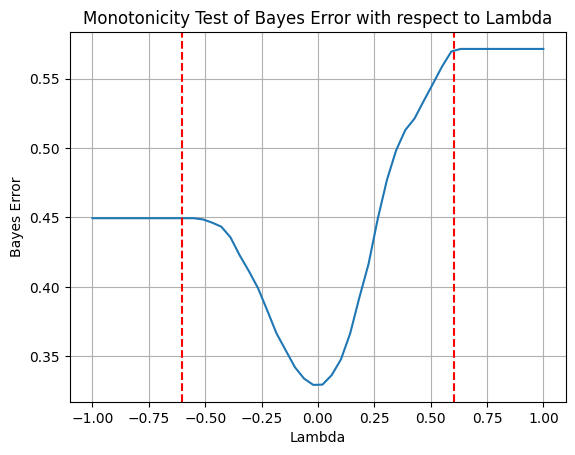

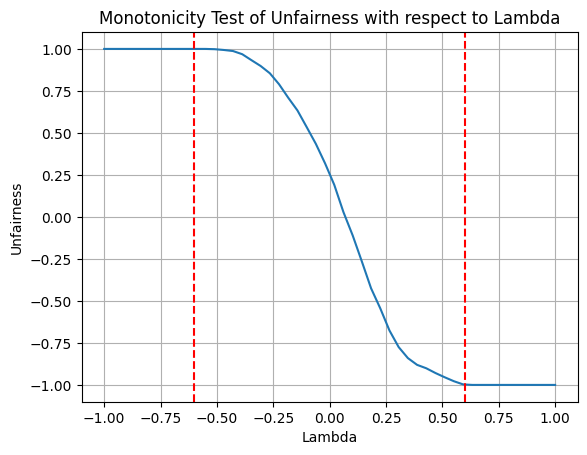

In [111]:
test_monotonicity(estimated_priors, D_est, 'DP')

In [113]:
from utils import return_tradeoff

true_tradeoff, true_bayes, true_unf = return_tradeoff(D_est, priors, constraint='DP', delta=0.001, eps=0.0001)

0.31853696413296384 0.26300437711946695 0.6017029328287606
lambda: 0.3008514664143803, Alpha_0: 0.25, Alpha_1: 0.8776722090261282, Error: 0.4629640848001957, Unfairness: -0.7629782339144595, Lam Min: 0, Lam Max: 0.6017029328287606
lambda: 0.15042573320719016, Alpha_0: 0.375, Alpha_1: 0.6888361045130641, Error: 0.3613737144611633, Unfairness: -0.30244326924513365, Lam Min: 0, Lam Max: 0.3008514664143803
lambda: 0.07521286660359508, Alpha_0: 0.4375, Alpha_1: 0.5944180522565321, Error: 0.32963458674159324, Unfairness: -0.023667070018972503, Lam Min: 0, Lam Max: 0.15042573320719016
lambda: 0.03760643330179754, Alpha_0: 0.46875, Alpha_1: 0.547209026128266, Error: 0.3210158288267792, Unfairness: 0.13189620400663293, Lam Min: 0, Lam Max: 0.07521286660359508
lambda: 0.05640964995269631, Alpha_0: 0.453125, Alpha_1: 0.5708135391923991, Error: 0.32471124968766674, Unfairness: 0.05217436770791317, Lam Min: 0.03760643330179754, Lam Max: 0.07521286660359508
lambda: 0.0658112582781457, Alpha_0: 0.445

In [114]:
est_tradeoff, est_bayes, est_unf = return_tradeoff(D_est, estimated_priors, constraint='DP', delta=0.001, eps=0.0001)

0.3289553996667084 0.26300437711946695 0.6017552182163188
lambda: 0.3008776091081594, Alpha_0: 0.25, Alpha_1: 0.8777546158427636, Error: 0.47338252033394024, Unfairness: -0.7629782339144595, Lam Min: 0, Lam Max: 0.6017552182163188
lambda: 0.1504388045540797, Alpha_0: 0.375, Alpha_1: 0.6888773079213818, Error: 0.37179214999490784, Unfairness: -0.30244326924513365, Lam Min: 0, Lam Max: 0.3008776091081594
lambda: 0.07521940227703985, Alpha_0: 0.4375, Alpha_1: 0.594438653960691, Error: 0.3400530222753378, Unfairness: -0.023667070018972503, Lam Min: 0, Lam Max: 0.1504388045540797
lambda: 0.03760970113851993, Alpha_0: 0.46875, Alpha_1: 0.5472193269803455, Error: 0.33143426436052376, Unfairness: 0.13189620400663293, Lam Min: 0, Lam Max: 0.07521940227703985
lambda: 0.05641455170777989, Alpha_0: 0.453125, Alpha_1: 0.5708289904705182, Error: 0.3351296852214113, Unfairness: 0.05217436770791317, Lam Min: 0.03760970113851993, Lam Max: 0.07521940227703985
lambda: 0.06581697699240988, Alpha_0: 0.4453

In [115]:
def plot_tradeoff(tradeoff, tradeoff_est, true_bayes, true_unf, predicted_points=None, lims=None):
    x = []
    y = []
    colors = []
    for key in tradeoff:
        #if key != -1:
        x.append(tradeoff[key][0])
        y.append(tradeoff[key][1])
        colors.append(tradeoff[key][2])
    x = np.array(x)
    y = np.array(y)
    plt.scatter(x, y, c=colors, cmap='viridis', label='True Trade-off')
    # x_y_spline = interp1d(x, y, kind='cubic')
    # X_ = np.linspace(x.min(), x.max(), 500)
    # Y_ = x_y_spline(X_)
    # plt.plot(X_, Y_, color='blue', linestyle='--', label='True Trade-off (spline)')
    # Draw a vertical line at the bayes optimal point
    plt.axvline(x=true_bayes, color='black', linestyle='--')
    plt.axhline(y=true_unf, color='black', linestyle='--')
    plt.colorbar(label='Lambda')
    x_est = []
    y_est = []
    colors_est = []
    for key in tradeoff_est:
        #if key != -1:
        x_est.append(tradeoff_est[key][0])
        y_est.append(tradeoff_est[key][1])
        colors_est.append(tradeoff_est[key][2])
    x_est = np.array(x_est)
    y_est = np.array(y_est)
    plt.scatter(x_est, y_est, c=colors_est, cmap='plasma', marker='x', label='Estimated Trade-off')
    # remove duplicates from x_est, y_est, colors_est
    # unique_indices = np.unique(x_est, return_index=True)[1]
    # u_x_est = x_est[unique_indices]
    # u_y_est = y_est[unique_indices]
    # u_colors_est = np.array(colors_est)[unique_indices]
    # x_y_spline_est = interp1d(u_x_est, u_y_est, kind='cubic')
    # X_est_ = np.linspace(x_est.min(), x_est.max(), 500)
    # Y_est_ = x_y_spline_est(X_est_)
    # plt.plot(X_est_, Y_est_, color='orange', linestyle='--', label='Estimated Trade-off (spline)')
    plt.colorbar(label='Lambda (Estimated)')
    if predicted_points is not None:
        if 'exp_grad' in predicted_points:
            unfs, errs, eps = predicted_points['exp_grad']
            unfs = np.array(unfs)
            errs = np.array(errs)
            plt.scatter(errs, unfs, c='green', marker='^', label='Fairlearn Exp-Grad')
        if 'pareto' in predicted_points:
            unfs_p, errs_p = list(predicted_points['pareto'].keys()), list(predicted_points['pareto'].values())
            unfs_p = np.array(unfs_p)
            errs_p = np.array(errs_p)
            plt.scatter(errs_p, unfs_p, c='red', marker='s', label='MIFPO')
        if 'fairret' in predicted_points:
            points_fairret = predicted_points['fairret']
            eps_fairret = []
            unfs_fairret = []
            errs_fairret = []
            for key in points_fairret:
                errs_fairret.append(points_fairret[key][0])
                unfs_fairret.append(points_fairret[key][1])
                eps_fairret.append(key)
            unfs_fairret = np.array(unfs_fairret)
            errs_fairret = np.array(errs_fairret)
            plt.scatter(errs_fairret, unfs_fairret, c='blue', marker='*', label='FairRet')
        if 'oxon' in predicted_points:
            unfs_oxon, errs_oxon = predicted_points['oxon']
            unfs_oxon = np.array(unfs_oxon)
            errs_oxon = np.array(errs_oxon)
            plt.scatter(errs_oxon, unfs_oxon, c='purple', marker='o', label='OxonFair')
        # Remove duplicates
        # unique_indices_exp = np.unique(errs, return_index=True)[1]
        # u_errs = errs[unique_indices_exp]
        # u_unfs = unfs[unique_indices_exp]
        # x_y_spline_exp = interp1d(u_errs, u_unfs, kind='cubic')
        # X_exp_ = np.linspace(errs.min(), errs.max(), 500)
        # Y_exp_ = x_y_spline_exp(X_exp_)
        # plt.plot(X_exp_, Y_exp_, color='green', linestyle='--', label='Fairlearn Exp-Grad (spline)')
        # unfs_fairret, errs_fairret, eps_fairret = predicted_points['fairret']
        # unfs_fairret = np.array(unfs_fairret)
        # errs_fairret = np.array(errs_fairret)
        # Remove duplicates
        # unique_indices_fairret = np.unique(errs_fairret, return_index=True)[1]
        # u_errs_fairret = errs_fairret[unique_indices_fairret]
        # u_unfs_fairret = unfs_fairret[unique_indices_fairret]
        # x_y_spline_fairret = interp1d(u_errs_fairret, u_unfs_fairret, kind='cubic')
        # X_fairret_ = np.linspace(errs_fairret.min(), errs_fairret.max(), 500)
        # Y_fairret_ = x_y_spline_fairret(X_fairret_)
        # plt.plot(X_fairret_, Y_fairret_, color='red', linestyle='--', label='FairRet (spline)')
        #plt.scatter(errs_fairret, unfs_fairret, c='red', marker='s', label='FairRet')
    plt.xlabel('Error')
    plt.ylabel('Unfairness')
    if lims is not None:
        plt.xlim(lims[0][0], lims[0][1])
        plt.ylim(lims[1][0], lims[1][1])
    plt.title('Trade-off Curve')
    plt.legend()

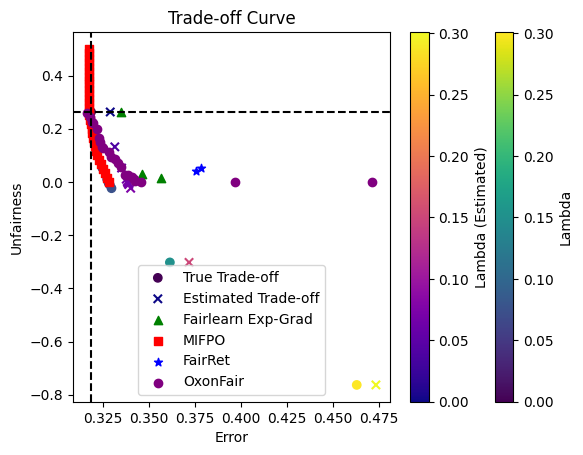

In [117]:
#from utils import plot_tradeoff
plot_tradeoff(true_tradeoff, est_tradeoff, true_bayes, true_unf, {'exp_grad':(unfs, errs, eps), 'pareto':pareto_front, 'fairret':points, 'oxon':(oxon_unfs, oxon_errs)})